# 02: RDF Knowledge Graph Generation, CAMEO Ontology & SPARQL
**NeuroSym-BD: Neuro-Symbolic Conflict Event Extraction & Reasoning**

This notebook explores the semantic layer:
1. **Ontology Schema**: Loading the Bangladesh CAMEO extension (`ontology/cameo_bd_extension.ttl`).
2. **RDF Generation**: Converting extracted event records into RDF Turtle format (`data/processed/events.ttl`).
3. **PROV-O Provenance**: Auditing multi-hop provenance links connecting graph nodes to news sentences.
4. **SPARQL In-Memory Querying**: Querying the RDF graph for high-violence clusters, actor involvement, and spatial statistics.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from rdflib import Graph, Namespace

cur = Path.cwd().resolve()
while cur != cur.parent:
    if (cur / "requirements.txt").exists():
        break
    cur = cur.parent
PROJECT_ROOT = cur
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: /Users/rohansmac/Documents/ml-research/neuro-symbolic-ai-workspace


## 1. Loading the RDF Knowledge Graph
We parse `data/processed/events.ttl` using `rdflib` and examine graph scale and predicates.


In [2]:
g = Graph()
ttl_path = PROJECT_ROOT / "data" / "processed" / "events.ttl"
g.parse(str(ttl_path), format="turtle")

print(f"RDF Graph loaded successfully from: {ttl_path.name}")
print(f"Total Triples in Knowledge Graph: {len(g)}")

# Predicate distribution
from collections import Counter
pred_counts = Counter([str(p).split('/')[-1].split('#')[-1] for s, p, o in g])
df_preds = pd.DataFrame(list(pred_counts.items()), columns=["Predicate", "Count"]).sort_values("Count", ascending=False)
display(df_preds)


RDF Graph loaded successfully from: events.ttl
Total Triples in Knowledge Graph: 1973


,Predicate,Count
7,actor,289
3,type,208
13,label,102
11,wasDerivedFrom,88
18,sentenceOffset,88
17,trigger,88
16,sourceSentence,88
14,eventId,88
1,date,88
12,sourceUrl,88


## 2. In-Memory SPARQL Queries
We execute standard SPARQL queries over the local RDF graph.


=== Top Event Locations ===


,District / Location,Event Count


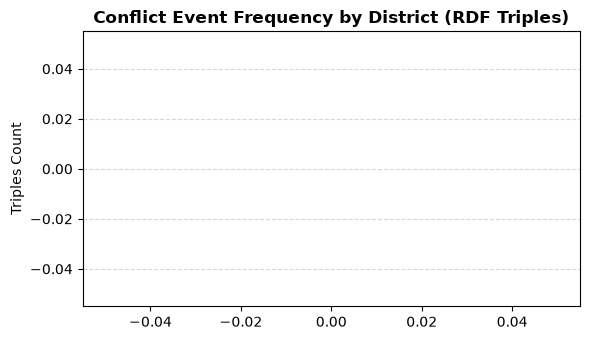

In [3]:
# SPARQL Query 1: Top Event Locations & Frequencies
q_locations = """
PREFIX cameo: <http://example.org/cameo/>
SELECT ?loc (COUNT(?evt) AS ?eventCount)
WHERE {
    ?evt cameo:hasLocation ?loc .
}
GROUP BY ?loc
ORDER BY DESC(?eventCount)
LIMIT 10
"""

res_loc = g.query(q_locations)
rows = [(str(row[0]).split('/')[-1], int(row[1])) for row in res_loc]
df_loc = pd.DataFrame(rows, columns=["District / Location", "Event Count"])
print("=== Top Event Locations ===")
display(df_loc)

# Plot Top Locations
plt.figure(figsize=(6, 3.5))
plt.bar(df_loc["District / Location"], df_loc["Event Count"], color="#348aa7")
plt.title("Conflict Event Frequency by District (RDF Triples)", fontweight="bold")
plt.ylabel("Triples Count")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 3. PROV-O Provenance Inspection
Every event node is grounded in its source article URL and sentence offset via W3C PROV-O.


In [4]:
# SPARQL Query 2: Sample PROV-O Provenance Links
q_prov = """
PREFIX cameo: <http://example.org/cameo/>
PREFIX prov:  <http://www.w3.org/ns/prov#>
SELECT ?evt ?code ?url ?sentIdx ?sentText
WHERE {
    ?evt cameo:hasCode ?code .
    OPTIONAL { ?evt prov:wasDerivedFrom ?src .
               ?src cameo:articleUrl ?url ;
                    cameo:sentenceIdx ?sentIdx .
               OPTIONAL { ?src cameo:sentenceText ?sentText }
    }
}
LIMIT 5
"""

res_prov = g.query(q_prov)
prov_records = []
for row in res_prov:
    prov_records.append({
        "Event URI": str(row[0]).split('/')[-1],
        "CAMEO Code": str(row[1]),
        "Source URL": str(row[2]) if row[2] else "N/A",
        "Sentence Index": str(row[3]) if row[3] else "N/A",
        "Snippet": str(row[4])[:80] + "..." if row[4] else "N/A"
    })

display(pd.DataFrame(prov_records))


""
